# Seoul Bike Sharing Demand Prediction

**Goal:** Classify whether an hour of the day will have **High Demand** or **Low Demand** for rental bikes in Seoul, using weather and calendar information.

**Approach**
1. Load and inspect the Seoul Bike dataset
2. Clean the data (duplicates, empty columns, missing values)
3. Explore the data visually (EDA)
4. Engineer features (date parts, one-hot encoding)
5. Split into train/test sets and binarize the target using the training median
6. Scale the features
7. Train a baseline model and a Logistic Regression model
8. Evaluate both with accuracy, confusion matrices and a classification report

**Dataset file:** `SeoulBikeData.csv`

## 0. Import Libraries
Libraries for data handling (`numpy`), (`pandas`), plotting (`matplotlib`, `seaborn`) and machine learning (`scikit-learn`).

In [16]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## 1. Loading the Dataset
The CSV is encoded in `cp949` (Korean), so the encoding is specified when reading it. We then print the size, first records, column names, data types and missing values.

In [17]:
data = pd.read_csv("SeoulBikeData.csv", encoding="cp949")

print("Seoul Bike dataset successfully loaded!")
print(f"\nDATASET SIZE: {data.shape[0]} Rows, {data.shape[1]} Columns")

Seoul Bike dataset successfully loaded!

DATASET SIZE: 8760 Rows, 14 Columns


In [18]:
print("FIRST 10 RECORDS:")
data.head(10)

FIRST 10 RECORDS:


,Date,Rented Bike Count,Hour,Temperature(캜),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(캜),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.00,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.00,0.0,0.0,Winter,No Holiday,Yes
5,01/12/2017,100,5,-6.4,37,1.5,2000,-18.7,0.00,0.0,0.0,Winter,No Holiday,Yes
6,01/12/2017,181,6,-6.6,35,1.3,2000,-19.5,0.00,0.0,0.0,Winter,No Holiday,Yes
7,01/12/2017,460,7,-7.4,38,0.9,2000,-19.3,0.00,0.0,0.0,Winter,No Holiday,Yes
8,01/12/2017,930,8,-7.6,37,1.1,2000,-19.8,0.01,0.0,0.0,Winter,No Holiday,Yes
9,01/12/2017,490,9,-6.5,27,0.5,1928,-22.4,0.23,0.0,0.0,Winter,No Holiday,Yes


In [19]:
print("COLUMN NAMES:")
print(data.columns)

print("\nDATASET INFORMATION:")
data.info()

print("\nMISSING VALUES:")
print(data.isnull().sum())

COLUMN NAMES:
Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(캜)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(캜)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='str')

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   str    
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(캜)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(캜)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)   

## 2. Cleaning the Dataset & Logging
The data is cleaned in three steps, with a log printed before and after:
1. Drop duplicate rows
2. Drop completely empty columns
3. Drop rows with missing values

In [20]:
# --- BEFORE CLEANING LOG ---
print("[BEFORE CLEANING]")
print(f"Total Rows: {len(data)}")
print(f"Total Columns: {data.shape[1]}")
print(f"Duplicate Rows Count: {data.duplicated().sum()}")
print("Missing Values Per Column:")
print(data.isnull().sum()[data.isnull().sum() > 0] if data.isnull().sum().sum() > 0 else "  No missing values found.")

[BEFORE CLEANING]
Total Rows: 8760
Total Columns: 14
Duplicate Rows Count: 0
Missing Values Per Column:
  No missing values found.


In [21]:
# --- PERFORMING CLEANING ---
# 1. Drop duplicate rows if present
initial_rows = len(data)
data = data.drop_duplicates()
duplicates_removed = initial_rows - len(data)

# 2. Drop completely empty columns
empty_columns = [c for c in data.columns if data[c].isnull().all()]
if empty_columns:
    data = data.drop(columns=empty_columns)

# 3. Drop rows with missing values (if any exist)
missing_before = data.isnull().sum().sum()
data = data.dropna()

# --- AFTER CLEANING LOG ---
print("[AFTER CLEANING]")
print(f"Total Rows: {len(data)} (Removed {duplicates_removed} duplicates)")
print(f"Total Columns: {data.shape[1]} (Dropped empty columns: {empty_columns if empty_columns else 'None'})")
print(f"Duplicate Rows Count: {data.duplicated().sum()}")
print(f"Missing Values Count: {data.isnull().sum().sum()}")
print(f"Final Dataset Shape: {data.shape}")
print("="*40)

[AFTER CLEANING]
Total Rows: 8760 (Removed 0 duplicates)
Total Columns: 14 (Dropped empty columns: None)
Duplicate Rows Count: 0
Missing Values Count: 0
Final Dataset Shape: (8760, 14)


## 3. Exploratory Data Analysis (EDA)
Descriptive statistics and visualizations to understand the patterns in bike rentals.

In [22]:
print("DESCRIPTIVE STATISTICS:")
pd.set_option('display.max_columns', None)
data.describe()

DESCRIPTIVE STATISTICS:


,Rented Bike Count,Hour,Temperature(캜),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(캜),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


### 3.1 Distribution of Bike Rental Counts
Shows how many bikes are typically rented per hour. The distribution is right-skewed, with many low-demand hours and a few very high ones.

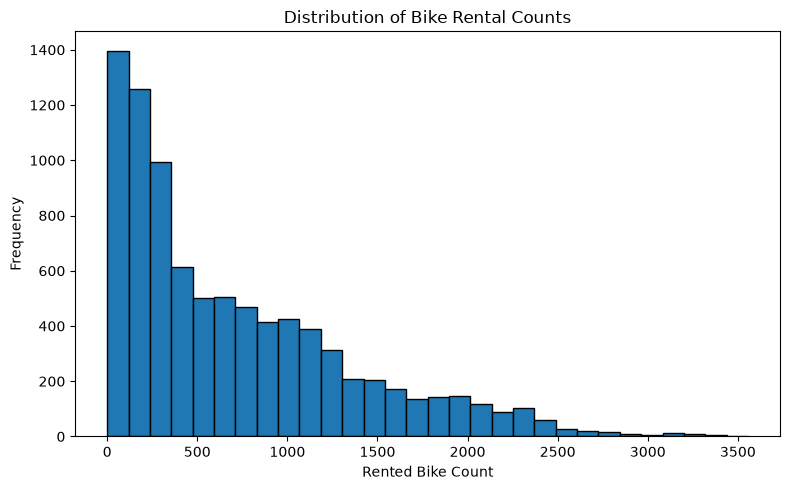

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(data["Rented Bike Count"], bins=30, edgecolor="black")
plt.title("Distribution of Bike Rental Counts")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 3.2 Average Rentals by Hour
Reveals daily usage patterns, such as commuting peaks in the morning and evening.

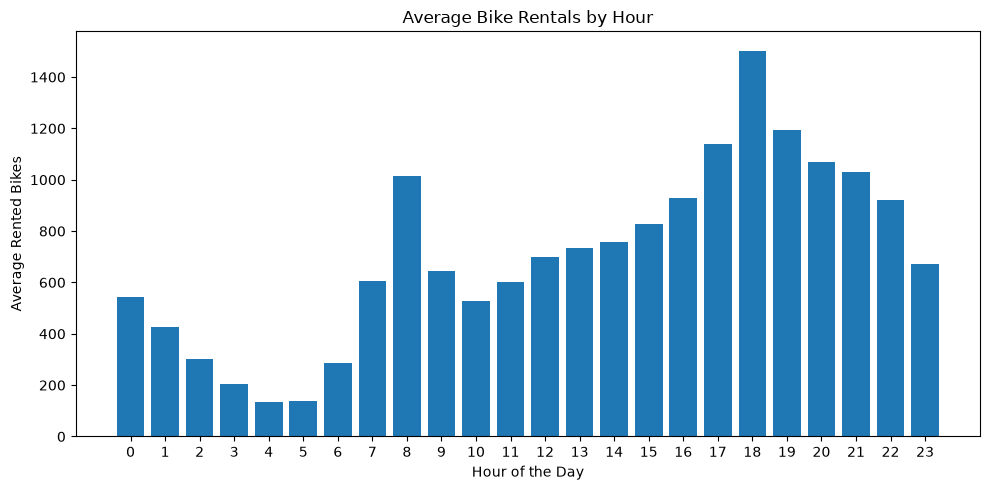

In [24]:
hourly_rentals = data.groupby("Hour")["Rented Bike Count"].mean()
plt.figure(figsize=(10, 5))
plt.bar(hourly_rentals.index, hourly_rentals.values)
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rented Bikes")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

### 3.3 Average Rentals by Season
Compares rental demand across seasons, from highest to lowest.

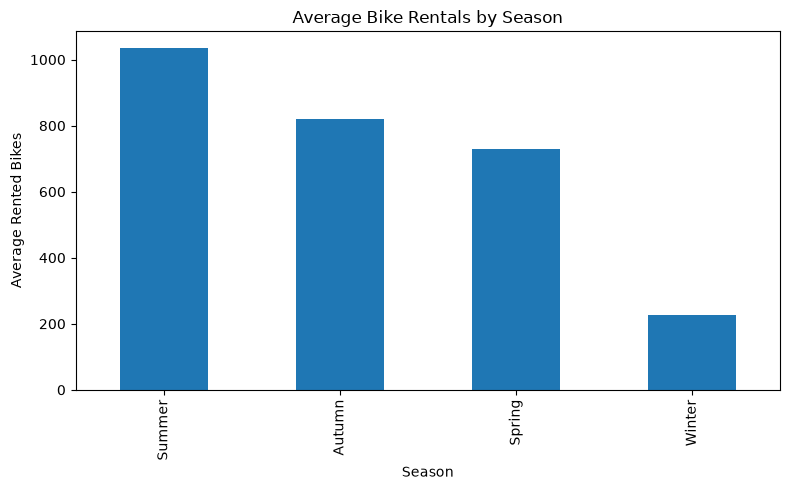

In [25]:
seasonal_rentals = data.groupby("Seasons")["Rented Bike Count"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
seasonal_rentals.plot(kind="bar")
plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rented Bikes")
plt.tight_layout()
plt.show()

### 3.4 Relationship between Temperature and Bike Rental Count
A scatter plot showing how rentals change with temperature. Note that the column name contains a garbled degree symbol (`캜`) caused by the `cp949` encoding, so it is referenced exactly as it appears.

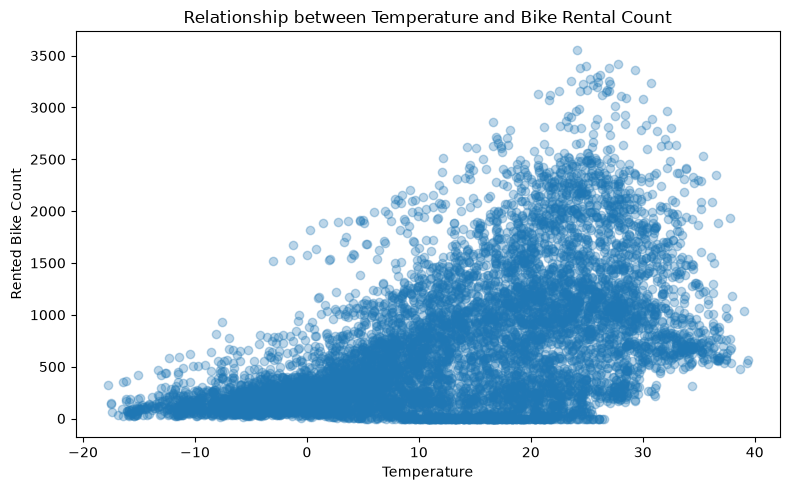

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["Temperature(캜)"],
    data["Rented Bike Count"],
    alpha=0.3
)

plt.title("Relationship between Temperature and Bike Rental Count")
plt.xlabel("Temperature")
plt.ylabel("Rented Bike Count")

plt.tight_layout()
plt.show()

### 3.5 Correlation Matrix Heatmap
Shows linear correlations between all numerical features, helping identify which variables relate most strongly to rental counts.

c:\Users\WINDOWS 11\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
C:\Users\WINDOWS 11\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


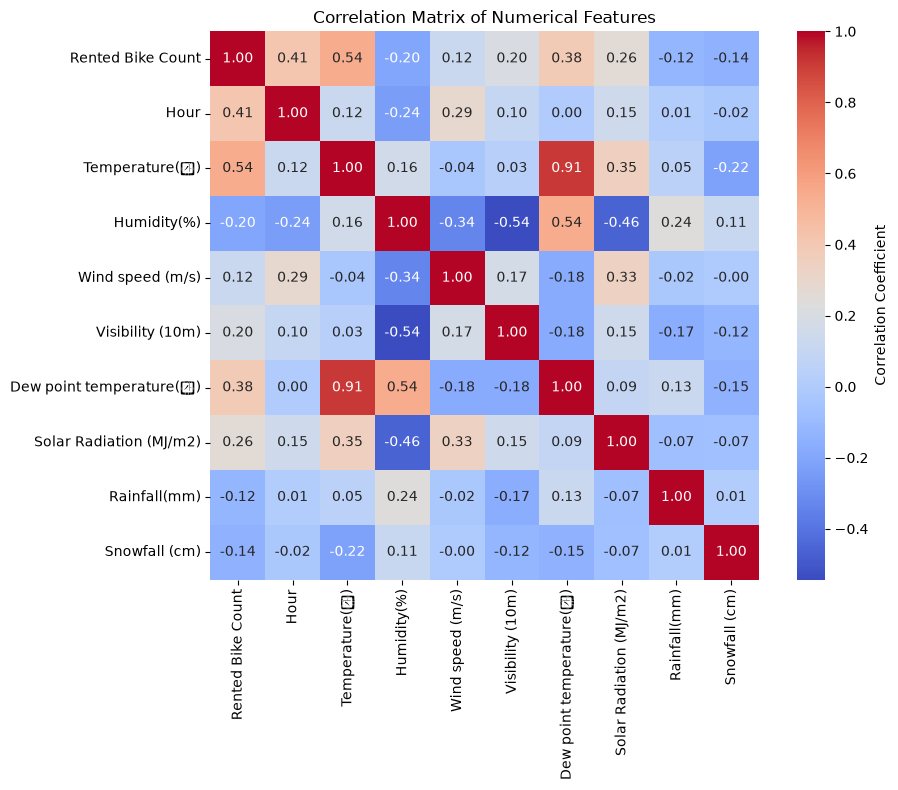

In [27]:
plt.figure(figsize=(10, 8))
numeric_data = data.select_dtypes(include=['float64', 'int64'])
correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## 4. Feature Preparation & Engineering
- Keep only records where the bike-sharing system was functioning, then drop the `Functioning Day` column (every remaining value is "Yes").
- Convert `Date` to a datetime and extract **Month** and **Day of Week**.
- Treat `Hour`, `Month` and `Day of Week` as categorical (strings) so they get one-hot encoded.
- Drop `Rented Bike Count` (the target), `Date`, and `Dew point temperature` (highly correlated with temperature) from the features.

In [28]:
# Keep records where the bike-sharing system is functioning
processed_data = data[data["Functioning Day"] == "Yes"].copy()

# Remove Functioning Day because every remaining value is Yes
processed_data = processed_data.drop(columns=["Functioning Day"])

print("Records after filtering:", len(processed_data))

# Datetime conversion
processed_data["Date"] = pd.to_datetime(
    processed_data["Date"],
    dayfirst=True,
    errors="coerce"
)

processed_data["Month"] = processed_data["Date"].dt.month.astype(str)
processed_data["Day of Week"] = processed_data["Date"].dt.day_of_week.astype(str)
processed_data["Hour"] = processed_data["Hour"].astype(str)

# Select features
X = processed_data.drop(columns=["Rented Bike Count", "Date", "Dew point temperature(캜)"])
y_continuous = processed_data["Rented Bike Count"]

raw_features = list(X.columns)

print(f"Total Base Features Selected ({len(raw_features)}):")
for feat in raw_features:
    print(f"  - {feat}")

Records after filtering: 8465
Total Base Features Selected (12):
  - Hour
  - Temperature(캜)
  - Humidity(%)
  - Wind speed (m/s)
  - Visibility (10m)
  - Solar Radiation (MJ/m2)
  - Rainfall(mm)
  - Snowfall (cm)
  - Seasons
  - Holiday
  - Month
  - Day of Week


## 5. Data Splitting & Target Binarization
- Split the data 80% train / 20% test (`random_state=42` for reproducibility).
- One-hot encode categorical features, then align the test columns to the training columns.
- Compute the **median of the training target only** (to avoid data leakage) and use it as the threshold: hours at or above it are **High Demand (1)**, otherwise **Low Demand (0)**.

In [37]:
X_train, X_test, y_train_continuous, y_test_continuous = train_test_split(
    X, y_continuous,
    test_size=0.2,
    random_state=42,
)

# One-hot encoding based on training data
X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

# Match test columns to training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Calculate the target median using ONLY the isolated training split data
train_median = y_train_continuous.median()
print(f"Non-Stratified Training Median Threshold: {train_median}")

# Binarize both targets using the training set's threshold
y_train = (y_train_continuous >= train_median).astype(int)
y_test = (y_test_continuous >= train_median).astype(int)

labels = ["Low Demand (0)", "High Demand (1)"]

for name, y_set in [("Training", y_train), ("Testing", y_test)]:
    counts = np.bincount(y_set, minlength=2)
    print(f"{name} set ({len(y_set)} samples):")
    for label, count in zip(labels, counts):
        print(f"  {label}: {count} ({count / len(y_set) * 100:.2f}%)")
    print()

Non-Stratified Training Median Threshold: 542.0
Training set (6772 samples):
  Low Demand (0): 3383 (49.96%)
  High Demand (1): 3389 (50.04%)

Testing set (1693 samples):
  Low Demand (0): 846 (49.97%)
  High Demand (1): 847 (50.03%)



## 6. Feature Scaling
Standardize features (zero mean, unit variance). The scaler is **fit on the training data only** and then applied to the test data.

In [30]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Baseline Model
A `DummyClassifier` that always predicts the most frequent class. Any useful model should beat this accuracy.

In [31]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_scaled, y_train)
dummy_pred = dummy_model.predict(X_test_scaled)
dummy_acc = accuracy_score(y_test, dummy_pred)

print("--- BASELINE MODEL EVALUATION ---")
print(f"Baseline Accuracy: {dummy_acc * 100:.2f}%")

--- BASELINE MODEL EVALUATION ---
Baseline Accuracy: 50.03%


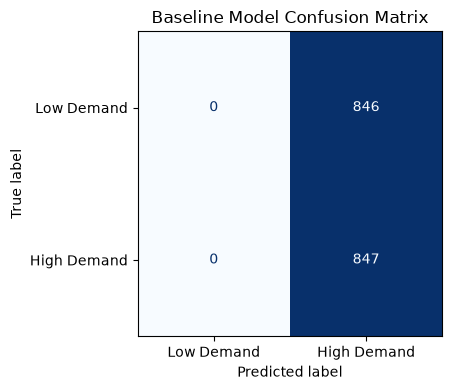

In [32]:
# Plot Baseline Confusion Matrix
dummy_cm = confusion_matrix(y_test, dummy_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(dummy_cm, display_labels=["Low Demand", "High Demand"]).plot(
    cmap="Blues", ax=ax, colorbar=False
)
plt.title("Baseline Model Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Model Training: Logistic Regression
Train a Logistic Regression classifier on the scaled training data.

In [33]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## 9. Model Evaluation
Evaluate Logistic Regression on the test set: accuracy, improvement over the baseline, a confusion matrix, and a per-class classification report (precision, recall, F1).

In [34]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print("--- LOGISTIC REGRESSION EVALUATION ---")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print(f"Improvement over Baseline: {(accuracy - dummy_acc) * 100:.2f}%")

--- LOGISTIC REGRESSION EVALUATION ---
Model Accuracy: 91.97%
Improvement over Baseline: 41.94%


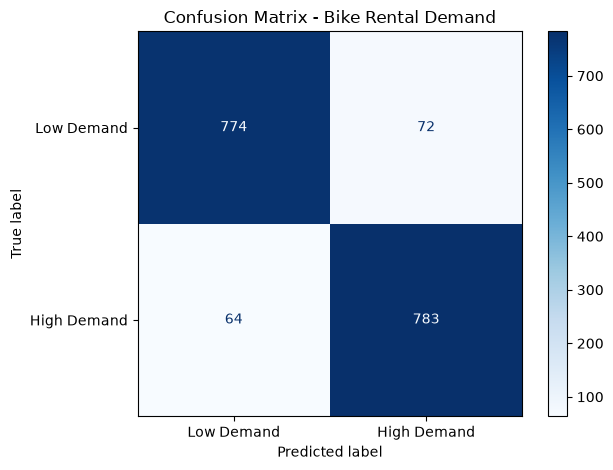

In [35]:
# Plot Logistic Regression Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Low Demand", "High Demand"],
    cmap="Blues"
)
plt.title("Confusion Matrix - Bike Rental Demand")
plt.tight_layout()
plt.show()

In [36]:
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred, target_names=["Low Demand", "High Demand"]))

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Low Demand       0.92      0.91      0.92       846
 High Demand       0.92      0.92      0.92       847

    accuracy                           0.92      1693
   macro avg       0.92      0.92      0.92      1693
weighted avg       0.92      0.92      0.92      1693

